# Chapitre 9 - Exercices 9.6 à 9.10

Ce notebook traite les exercices du chapitre 9 consacrés à l'ordre, aux horloges
logiques et au consensus :

- **9.6** : horloges de Lamport et vectorielles à la main (calcul) ;
- **9.7** : identifiants horodatés et décalage des horloges, une formule et sa
  vérification (calcul et mini-lab) ;
- **9.8** : taille et placement d'une grappe de consensus face aux pannes corrélées
  (calcul) ;
- **9.9** : casser Raft en supprimant la restriction d'élection (mini-lab) ;
- **9.10** : régler le délai d'élection (mini-lab).

In [1]:
import math
from math import comb

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import consistency as cs
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## Exercice 9.6 : horloges de Lamport et vectorielles à la main

**Énoncé.** Trois nœuds P, Q, R. Dans l'ordre du temps réel : P a un événement local
`p1` ; R a un événement local `r1` ; P envoie m1 à Q (`p2`) ; R envoie m3 à P (`r2`) ; Q
reçoit m1 (`q1`) ; P reçoit m3 (`p3`) ; Q envoie m2 à R (`q2`) ; Q a un événement local
`q3` ; R reçoit m2 (`r3`).

1. Calculer le compteur de Lamport et l'horloge vectorielle [P, Q, R] de chaque événement.
2. Pour les paires (`p3`, `q2`), (`r1`, `q3`) et (`p1`, `r3`), dire si elles sont
   causalement liées ou concurrentes, et comparer avec l'ordre de Lamport.
3. A-t-on « $L(a) < L(b) \Rightarrow a \to b$ » ? Et « $V(a) < V(b) \Rightarrow a \to b$ » ?

**Rappels.** Relation « s'est produit avant », horloges de Lamport et vectorielles (cours 2,
sections 1, 4 et 5 ; section *Lamport timestamps*).

**Solution.**

*1.* Lamport (incrément à chaque événement, rattrapage à la réception) : `p1` = 1, `r1` = 1,
`p2` = 2, `r2` = 2, `q1` = max(0, 2) + 1 = 3, `p3` = max(2, 2) + 1 = 3, `q2` = 4, `q3` = 5,
`r3` = max(2, 4) + 1 = 5. Vecteurs : `p1` [1,0,0], `r1` [0,0,1], `p2` [2,0,0], `r2` [0,0,2],
`q1` [2,1,0], `p3` [3,0,2], `q2` [2,2,0], `q3` [2,3,0], `r3` [2,2,3].

*2.* (`p3`, `q2`) : [3,0,2] et [2,2,0], chacun plus grand sur une composante :
**concurrents** ; Lamport les range pourtant (3, P) < (4, Q). (`r1`, `q3`) : [0,0,1] et
[2,3,0] : **concurrents** ; Lamport dit 1 < 5. (`p1`, `r3`) : [1,0,0] ≤ [2,2,3] : `p1` → `r3`
(chaîne p1, p2, m1, q1, q2, m2, r3), et Lamport est cohérent (1 < 5).

*3.* Non pour Lamport : la causalité implique l'ordre des compteurs, pas l'inverse
(contre-exemple `p3`, `q2`). Oui pour les vecteurs : $V(a) < V(b) \Leftrightarrow a \to b$.

In [2]:
nodes = ["P", "Q", "R"]
lam = {n: cs.LamportClock(n) for n in nodes}
vec = {n: cs.VectorClock(n, nodes) for n in nodes}
sent, ev = {}, {}
for kind, node, name, m in [("local", "P", "p1", None), ("local", "R", "r1", None), ("send", "P", "p2", "m1"),
                            ("send", "R", "r2", "m3"), ("recv", "Q", "q1", "m1"), ("recv", "P", "p3", "m3"),
                            ("send", "Q", "q2", "m2"), ("local", "Q", "q3", None), ("recv", "R", "r3", "m2")]:
    if kind == "recv":
        lam[node].observe(sent[m][0]); vec[node].observe(sent[m][1])
    ev[name] = (lam[node].tick(), vec[node].tick())
    if kind == "send":
        sent[m] = ev[name]
display(pd.DataFrame({k: dict(lamport=v[0][0], vecteur=list(v[1].values())) for k, v in ev.items()}).T)
pd.DataFrame([dict(paire=f"({a}, {b})", relation=cs.vc_compare(ev[a][1], ev[b][1]), lamport=f"{ev[a][0]} vs {ev[b][0]}")
              for a, b in [("p3", "q2"), ("r1", "q3"), ("p1", "r3")]])

,lamport,vecteur
p1,1,"[1, 0, 0]"
r1,1,"[0, 0, 1]"
p2,2,"[2, 0, 0]"
r2,2,"[0, 0, 2]"
q1,3,"[2, 1, 0]"
p3,3,"[3, 0, 2]"
q2,4,"[2, 2, 0]"
q3,5,"[2, 3, 0]"
r3,5,"[2, 2, 3]"


,paire,relation,lamport
0,"(p3, q2)",||,"(3, 'P') vs (4, 'Q')"
1,"(r1, q3)",||,"(1, 'R') vs (5, 'Q')"
2,"(p1, r3)",<,"(1, 'P') vs (5, 'R')"


Le code retrouve exactement les valeurs calculées à la main.

> **À retenir.** $a \to b \Rightarrow L(a) < L(b)$, mais pas la réciproque ; les horloges
> vectorielles caractérisent exactement la causalité.

## Exercice 9.7 : identifiants horodatés et décalage des horloges

**Énoncé.** Des identifiants sont formés de (heure locale en ms, numéro de nœud,
séquence). Deux demandes arrivent à $g$ ms d'intervalle sur des nœuds tirés au hasard.

1. Deux nœuds, l'horloge du nœud B en avance de $\delta$ sur celle de A. Pour quelle
   probabilité la seconde demande reçoit-elle un identifiant plus petit ? (On néglige
   l'arrondi à la milliseconde.)
2. $n$ nœuds dont les décalages sont uniformes et indépendants sur $[-\delta/2, \delta/2]$.
   Montrer que pour $0 \le g \le \delta$,
   $P(\text{inversion}) = (1 - 1/n)\,(\delta - g)^2 / (2\delta^2)$.
3. Vérifier les deux formules par simulation (`cs.assign_ids`, `cs.inversion_curve`).

**Rappels.** Générateurs distribués et horloge murale (cours 2, section 3 ; section
*Noncausal sequence number generators*), décalage des horloges (chapitre 8).

**Solution.**

*1.* Sur le même nœud, l'ordre est respecté. Si la première demande va sur A (horloge
exacte) et la seconde sur B (en avance), l'ordre est respecté aussi. Seul le cas
« première sur B, seconde sur A » pose problème : les heures lues sont $t + \delta$ et
$t + g$, inversées si $g < \delta$. D'où $P = \tfrac14 \cdot \mathbb{1}[g < \delta]$ avec
deux nœuds équiprobables.

*2.* Inversion si les nœuds diffèrent (probabilité $1 - 1/n$) et si
$o_1 - o_2 > g$, où $o_1, o_2$ sont les décalages. La différence $D$ de deux uniformes sur
$[-\delta/2, \delta/2]$ suit une loi triangulaire sur $[-\delta, \delta]$ de densité
$(\delta - |d|)/\delta^2$ ; donc $P(D > g) = \int_g^\delta (\delta - d)/\delta^2\,\mathrm{d}d
= (\delta - g)^2/(2\delta^2)$.

*3.* Simulation ci-dessous. On simule 20 000 demandes par seconde pour que l'écart réel
entre deux demandes soit très proche de $g$ ; à $n$ nœuds, les décalages sont tirés une
fois pour toutes par graine, d'où une moyenne sur 40 graines.

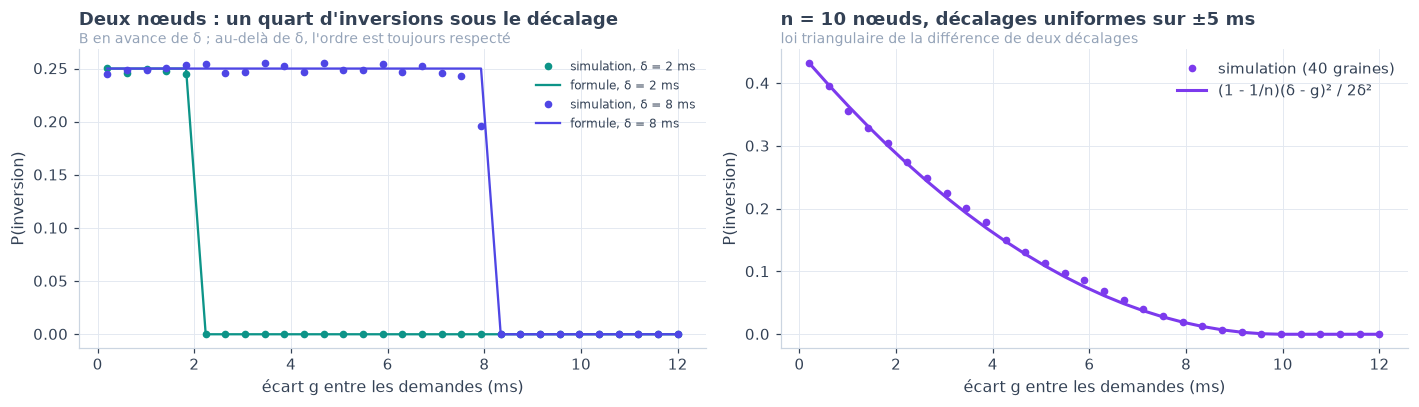

In [3]:
N = 200_000
times = np.sort(rng.uniform(0, 10.0, N))           # 20 000 demandes/s : écart réel ≈ g à 0,05 ms près
gaps = np.linspace(0.0002, 0.012, 30)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 3.8))
for delta, c in [(0.002, TEAL), (0.008, INDIGO)]:
    nodes_ = rng.integers(0, 2, N)
    ids = cs.assign_ids("wallclock", times, nodes_, 2, offsets=[0.0, delta], tick=1e-5)
    ax.plot(gaps * 1000, cs.inversion_curve(times, ids, gaps, 20000, seed=1), "o", color=c, ms=4,
            label=f"simulation, δ = {delta * 1000:.0f} ms")
    ax.plot(gaps * 1000, 0.25 * (gaps < delta), "-", color=c, lw=1.5, label=f"formule, δ = {delta * 1000:.0f} ms")
ax.set_xlabel("écart g entre les demandes (ms)"); ax.set_ylabel("P(inversion)")
ax.set_title("Deux nœuds : un quart d'inversions sous le décalage")
subtitle(ax, "B en avance de δ ; au-delà de δ, l'ordre est toujours respecté")
ax.legend(fontsize=8)
delta, n = 0.010, 10
curves = []
for seed in range(40):
    g_ = np.random.default_rng(100 + seed)
    offs = g_.uniform(-delta / 2, delta / 2, n)
    nodes_ = g_.integers(0, n, N)
    ids = cs.assign_ids("wallclock", times, nodes_, n, offsets=offs, tick=1e-5)
    curves.append(cs.inversion_curve(times, ids, gaps, 5000, seed=seed))
ax2.plot(gaps * 1000, np.mean(curves, axis=0), "o", color=VIOLET, ms=4, label="simulation (40 graines)")
th = (1 - 1 / n) * np.clip(delta - gaps, 0, None) ** 2 / (2 * delta ** 2)
ax2.plot(gaps * 1000, th, color=VIOLET, label="(1 - 1/n)(δ - g)² / 2δ²")
ax2.set_xlabel("écart g entre les demandes (ms)"); ax2.set_ylabel("P(inversion)")
ax2.set_title("n = 10 nœuds, décalages uniformes sur ±5 ms")
subtitle(ax2, "loi triangulaire de la différence de deux décalages")
ax2.legend()
plt.tight_layout(); plt.show()

Les simulations suivent les formules. À écart nul, près d'une paire de demandes sur deux
(45 % avec 10 nœuds) est inversée : pour des événements rapprochés, un horodatage
physique ne vaut guère mieux qu'un tirage à pile ou face.

> **À retenir.** Avec des horodatages physiques, deux événements séparés de moins que le
> décalage des horloges sont ordonnés au hasard ; au-delà, l'ordre est correct. Le
> décalage borne la « résolution causale » du système.